# 02 – Thống kê mô tả (EDA) & Ước lượng khoảng
**Thành viên 2 (Uyên)** · Nguồn dữ liệu: CarDekho – *Car details v3* · Quy ước nhóm: α = 0,05; `random_state = 42`; giá tính bằng INR.

> ⚠️ Chỉ chạy kết quả chính thức khi `cleaned_cars.csv` **v1.0** đã được Khoa đóng băng (mốc 2).

**Mục lục:** 0. Cấu hình · 1. Đọc dữ liệu · 2. Thống kê mô tả biến định lượng · 3. Biến phân loại · 4. Phân phối và biến đổi log · 5. Boxplot · 6. Tương quan · 7. Khoảng tin cậy 95% · 8. Tóm tắt số liệu cho báo cáo

## 0. Cấu hình và quy chuẩn hình/bảng

In [3]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportion_confint

SEED, ALPHA = 42, 0.05
rng = np.random.default_rng(SEED)

# Đường dẫn: chỉnh lại nếu chạy trên Kaggle (vd. "/kaggle/input/<ten-dataset>/cleaned_cars.csv")
import glob
CANDIDATES = (glob.glob("/kaggle/input/**/cleaned_cars.csv", recursive=True)
              + ["../data/processed/cleaned_cars.csv", "data/processed/cleaned_cars.csv", "cleaned_cars.csv"])
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), CANDIDATES[0])
FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# Quy chuẩn chung: 300 dpi, nhãn tiếng Việt
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "font.family": "DejaVu Sans",
                     "axes.titlesize": 11, "axes.labelsize": 10})
sns.set_theme(style="whitegrid", font="DejaVu Sans")
SRC = "Nguồn: CarDekho (Car details v3), nhóm tính toán"

def save_fig(name, caption):
    """Lưu hình 300 dpi, ghi nguồn dưới hình. Số hình đặt tay trong `name` (vd. hinh_3_1)."""
    plt.figtext(0.01, -0.02, f"{caption}. {SRC}", fontsize=8, ha="left", style="italic")
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=300, bbox_inches="tight")
    plt.show()

def vnd(x, pos=None):
    return f"{x/1e5:,.0f}"   # trục giá: đơn vị trăm nghìn INR

## 1. Đọc dữ liệu và kiểm tra nhanh

In [4]:
df = pd.read_csv(DATA_PATH)
print("Số dòng, số cột:", df.shape)

# Bổ sung biến phái sinh nếu file của Khoa chưa có
if "car_age" not in df.columns:
    df["car_age"] = 2020 - df["year"]
if "brand" not in df.columns:
    df["brand"] = df["name"].str.split().str[0]
# Nếu mileage/engine/max_power còn ở dạng chữ ("23.4 kmpl"), tách số
for c in ["mileage", "engine", "max_power", "seats"]:
    if c in df.columns and df[c].dtype == object:
        df[c] = pd.to_numeric(df[c].astype(str).str.extract(r"([\d.]+)")[0], errors="coerce")

if "log_price" not in df.columns:
    df["log_price"] = np.log(df["selling_price"])

# mileage có 2 đơn vị (kmpl: xăng, dầu | km/kg: CNG, LPG) -> chỉ dùng phần kmpl để thống kê
if "mileage_unit" in df.columns:
    df["mileage_kmpl"] = df["mileage"].where(df["mileage_unit"].astype(str).str.lower() == "kmpl")
else:
    df["mileage_kmpl"] = df["mileage"]
print("Số xe có mileage kmpl:", df["mileage_kmpl"].notna().sum(), "| số dòng:", len(df))
print("Số giá trị khuyết theo cột:"); print(df.isna().sum()[df.isna().sum() > 0])
df.head()

Số dòng, số cột: (6693, 22)
Số xe có mileage kmpl: 6608 | số dòng: 6693
Số giá trị khuyết theo cột:
torque_nm        3
mileage_kmpl    85
dtype: int64


,raw_index,name,brand,model,year,car_age,selling_price,log_price,km_driven,fuel,...,transmission,owner,owner_rank,mileage,mileage_unit,engine,max_power,torque_nm,seats,mileage_kmpl
0,0,Maruti Swift Dzire VDI,Maruti,Swift,2014,6,450000,13.017003,145500,Diesel,...,Manual,First Owner,1,23.40,kmpl,1248,74.00,190.00,5,23.40
1,1,Skoda Rapid 1.5 TDI Ambition,Skoda,Rapid,2014,6,370000,12.821258,120000,Diesel,...,Manual,Second Owner,2,21.14,kmpl,1498,103.52,250.00,5,21.14
2,2,Honda City 2017-2020 EXi,Honda,City,2006,14,158000,11.970350,140000,Petrol,...,Manual,Third Owner,3,17.70,kmpl,1497,78.00,124.54,5,17.70
3,3,Hyundai i20 Sportz Diesel,Hyundai,i20,2010,10,225000,12.323856,127000,Diesel,...,Manual,First Owner,1,23.00,kmpl,1396,90.00,219.67,5,23.00
4,4,Maruti Swift VXI BSIII,Maruti,Swift,2007,13,130000,11.775290,120000,Petrol,...,Manual,First Owner,1,16.10,kmpl,1298,88.20,112.78,5,16.10


**Ghi chú cho báo cáo (3.1.1):** ghi n và số biến sau làm sạch theo nhật ký của Khoa. Nếu `mileage` còn lẫn hai đơn vị (kmpl và km/kg), theo nhật ký của Khoa, `mileage` là kmpl cho xăng/dầu và km/kg cho CNG/LPG, nên notebook chỉ dùng phần kmpl (cột `mileage_kmpl`) cho Bảng 3.1 và heatmap. Ghi chú này vào dưới Bảng 3.1.

## 2. Thống kê mô tả biến định lượng
**📘 Kiến thức XSTK**
- *Đặc trưng vị trí:* trung bình mẫu $\bar x=\frac1n\sum x_i$, trung vị, phân vị Q1, Q3.
- *Đặc trưng phân tán:* phương sai mẫu $s^2=\frac{1}{n-1}\sum (x_i-\bar x)^2$ (chia n−1 để không chệch), độ lệch chuẩn $s$, khoảng tứ phân vị IQR = Q3 − Q1.
- *Hình dạng:* skewness > 0 là lệch phải (đuôi dài bên phải, thường mean > median); kurtosis đo độ nhọn/dày đuôi. `pandas.kurt()` trả về **kurtosis dư** (phân phối chuẩn = 0).
- Trung bình và SD **nhạy với ngoại lai**; trung vị và IQR là thống kê **vững (robust)**.

In [5]:
cols = [c for c in ["selling_price", "km_driven", "car_age", "engine", "max_power", "mileage_kmpl", "seats"] if c in df.columns]
q1, q3 = df[cols].quantile(.25), df[cols].quantile(.75)
bang31 = pd.DataFrame({
    "n": df[cols].count(), "Trung bình": df[cols].mean(), "Trung vị": df[cols].median(),
    "Độ lệch chuẩn": df[cols].std(ddof=1), "Q1": q1, "Q3": q3, "IQR": q3 - q1,
    "Độ lệch (skew)": df[cols].skew(), "Kurtosis dư": df[cols].kurt()})
bang31["Mean/Median"] = bang31["Trung bình"] / bang31["Trung vị"]
bang31 = bang31.round(2)
bang31.to_csv(f"{FIG_DIR}/bang_3_1.csv", encoding="utf-8-sig")
print("Bảng 3.1. Thống kê mô tả biến định lượng (kurtosis dư: chuẩn = 0). " + SRC)
bang31

Bảng 3.1. Thống kê mô tả biến định lượng (kurtosis dư: chuẩn = 0). Nguồn: CarDekho (Car details v3), nhóm tính toán


,n,Trung bình,Trung vị,Độ lệch chuẩn,Q1,Q3,IQR,Độ lệch (skew),Kurtosis dư,Mean/Median
selling_price,6693,523223.33,420000.00,508245.49,250000.0,650000.00,400000.00,5.46,52.53,1.25
km_driven,6693,72851.90,68600.00,48245.23,38000.0,100000.00,62000.00,1.62,6.29,1.06
car_age,6693,6.39,6.00,3.90,3.0,9.00,6.00,0.94,1.18,1.06
engine,6693,1430.49,1248.00,493.14,1197.0,1498.00,301.00,1.22,0.98,1.15
max_power,6693,87.71,81.83,31.64,68.0,100.00,32.00,1.71,5.49,1.07
mileage_kmpl,6608,19.48,19.40,3.91,16.8,22.48,5.68,0.03,-0.37,1.00
seats,6693,5.44,5.00,0.98,5.0,5.00,0.00,1.94,3.58,1.09


**Cách nhận xét:** biến nào có Mean/Median ≫ 1 và skew lớn → lệch phải mạnh, nên dùng trung vị để nói về "giá điển hình". Viết theo mẫu *số liệu → nhận xét → ý nghĩa thực tiễn*.

## 3. Biến phân loại: bảng tần số, tỷ lệ % và biểu đồ cột
**📘 Kiến thức XSTK:** `fuel`, `seller_type`, `transmission` là dữ liệu định tính **danh nghĩa**; `owner` là **thứ bậc**. Với biến định tính không tính trung bình, chỉ dùng **tần số**, **tần suất (tỷ lệ)** và **mốt**.

In [6]:
cat_cols = [c for c in ["fuel", "seller_type", "transmission", "owner"] if c in df.columns]
freq_tables = {}
for c in cat_cols:
    t = df[c].value_counts().to_frame("Tần số")
    t["Tỷ lệ (%)"] = (t["Tần số"] / len(df) * 100).round(1)
    freq_tables[c] = t
    print(f"\nBảng 3.2 ({c})"); display(t)

top10 = df["brand"].value_counts().head(10).to_frame("Tần số")
top10["Tỷ lệ (%)"] = (top10["Tần số"] / len(df) * 100).round(1)
print("\nBảng 3.2 (10 hãng nhiều xe nhất)"); display(top10)

with pd.ExcelWriter(f"{FIG_DIR}/bang_3_2_tan_so.xlsx") as w:
    for c, t in freq_tables.items(): t.to_excel(w, sheet_name=c)
    top10.to_excel(w, sheet_name="top10_brand")


Bảng 3.2 (fuel)


,Tần số,Tỷ lệ (%)
fuel,,
Diesel,3651,54.5
Petrol,2957,44.2
CNG,50,0.7
LPG,35,0.5



Bảng 3.2 (seller_type)


,Tần số,Tỷ lệ (%)
seller_type,,
Individual,6009,89.8
Dealer,684,10.2



Bảng 3.2 (transmission)


,Tần số,Tỷ lệ (%)
transmission,,
Manual,6127,91.5
Automatic,566,8.5



Bảng 3.2 (owner)


,Tần số,Tỷ lệ (%)
owner,,
First Owner,4165,62.2
Second Owner,1883,28.1
Third Owner,492,7.4
Fourth & Above Owner,153,2.3



Bảng 3.2 (10 hãng nhiều xe nhất)


,Tần số,Tỷ lệ (%)
brand,,
Maruti,2087,31.2
Hyundai,1206,18.0
Mahindra,706,10.5
Tata,632,9.4
Honda,360,5.4
Ford,353,5.3
Toyota,324,4.8
Chevrolet,216,3.2
Renault,206,3.1


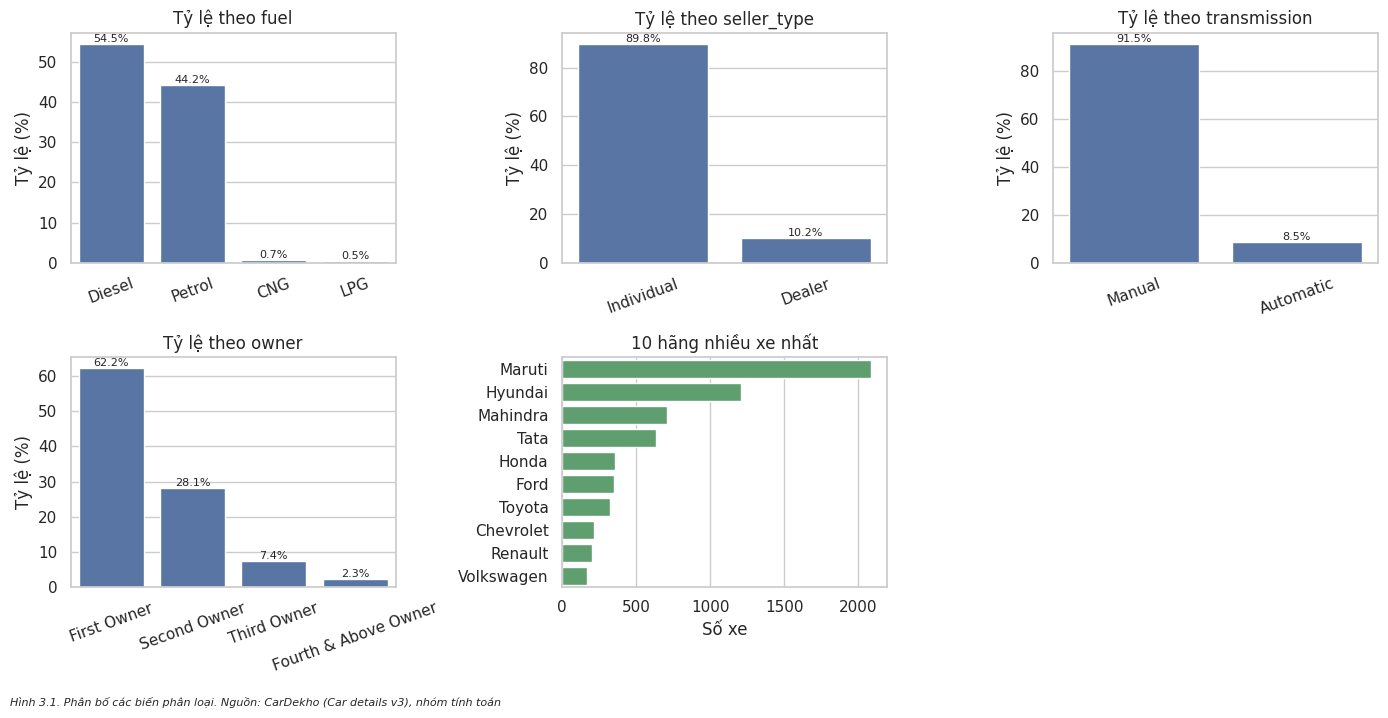

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.ravel(), cat_cols):
    t = freq_tables[c]
    sns.barplot(x=t.index, y=t["Tỷ lệ (%)"], ax=ax, color="#4C72B0")
    ax.set_title(f"Tỷ lệ theo {c}"); ax.set_xlabel(""); ax.set_ylabel("Tỷ lệ (%)")
    ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(t["Tỷ lệ (%)"]): ax.text(i, v, f"{v}%", ha="center", va="bottom", fontsize=8)
ax = axes.ravel()[len(cat_cols)]
sns.barplot(y=top10.index, x=top10["Tần số"], ax=ax, color="#55A868")
ax.set_title("10 hãng nhiều xe nhất"); ax.set_xlabel("Số xe"); ax.set_ylabel("")
for a in axes.ravel()[len(cat_cols)+1:]: a.axis("off")
plt.tight_layout()
save_fig("hinh_3_1", "Hình 3.1. Phân bố các biến phân loại")

## 4. Phân phối của giá và phép biến đổi log
**📘 Kiến thức XSTK**
- **Histogram** ước lượng hình dạng phân phối; **KDE** ước lượng mật độ xác suất trơn.
- Dữ liệu lệch phải mạnh → **biến đổi log** kéo về gần đối xứng và ổn định phương sai. Mô hình/kiểm định của TV3, TV4 dùng `log(selling_price)`, nên **ghi rõ lý do** ở đây.
- **Q-Q plot** so sánh phân vị mẫu với phân vị chuẩn; đây là công cụ chính thay Shapiro-Wilk khi n > 5.000.

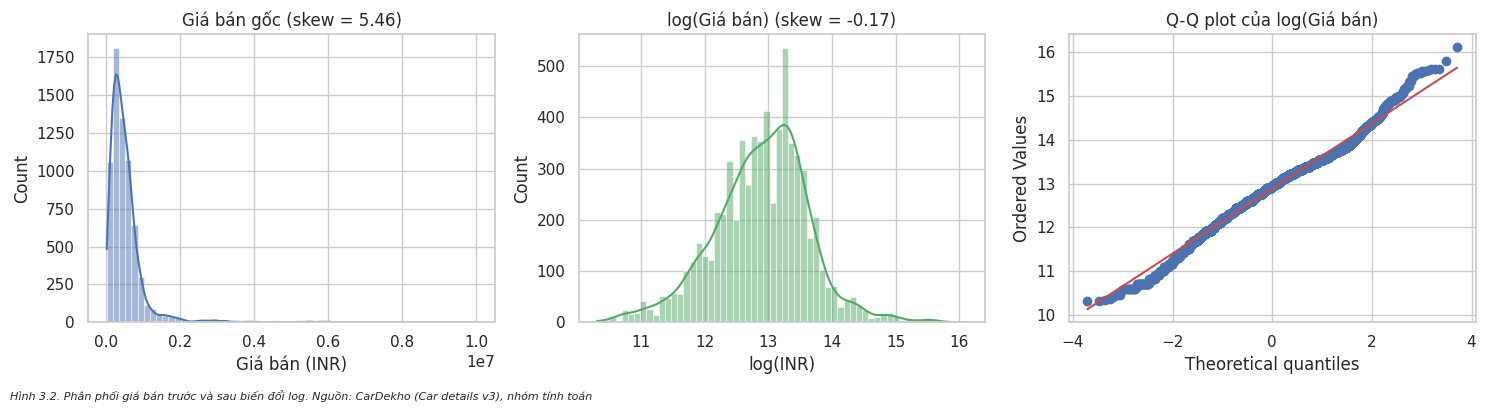

Skewness: 5.46 -> -0.17 | Mean/Median gốc = 1.25


In [8]:
sk_before, sk_after = df["selling_price"].skew(), df["log_price"].skew()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["selling_price"], kde=True, bins=60, ax=ax[0], color="#4C72B0")
ax[0].set_title(f"Giá bán gốc (skew = {sk_before:.2f})"); ax[0].set_xlabel("Giá bán (INR)")
sns.histplot(df["log_price"], kde=True, bins=60, ax=ax[1], color="#55A868")
ax[1].set_title(f"log(Giá bán) (skew = {sk_after:.2f})"); ax[1].set_xlabel("log(INR)")
stats.probplot(df["log_price"], dist="norm", plot=ax[2]); ax[2].set_title("Q-Q plot của log(Giá bán)")
plt.tight_layout()
save_fig("hinh_3_2", "Hình 3.2. Phân phối giá bán trước và sau biến đổi log")
print(f"Skewness: {sk_before:.2f} -> {sk_after:.2f} | Mean/Median gốc = {df.selling_price.mean()/df.selling_price.median():.2f}")

## 5. Boxplot theo nhiên liệu, hộp số và hãng
**📘 Kiến thức XSTK:** boxplot hiển thị 5 số (min, Q1, median, Q3, max); điểm ngoài khoảng $[Q_1-1{,}5\,IQR,\ Q_3+1{,}5\,IQR]$ được vẽ là ngoại lai. Ngoại lai trên boxplot **không đồng nghĩa với sai số**: xe sang giá cao là quan sát thật.

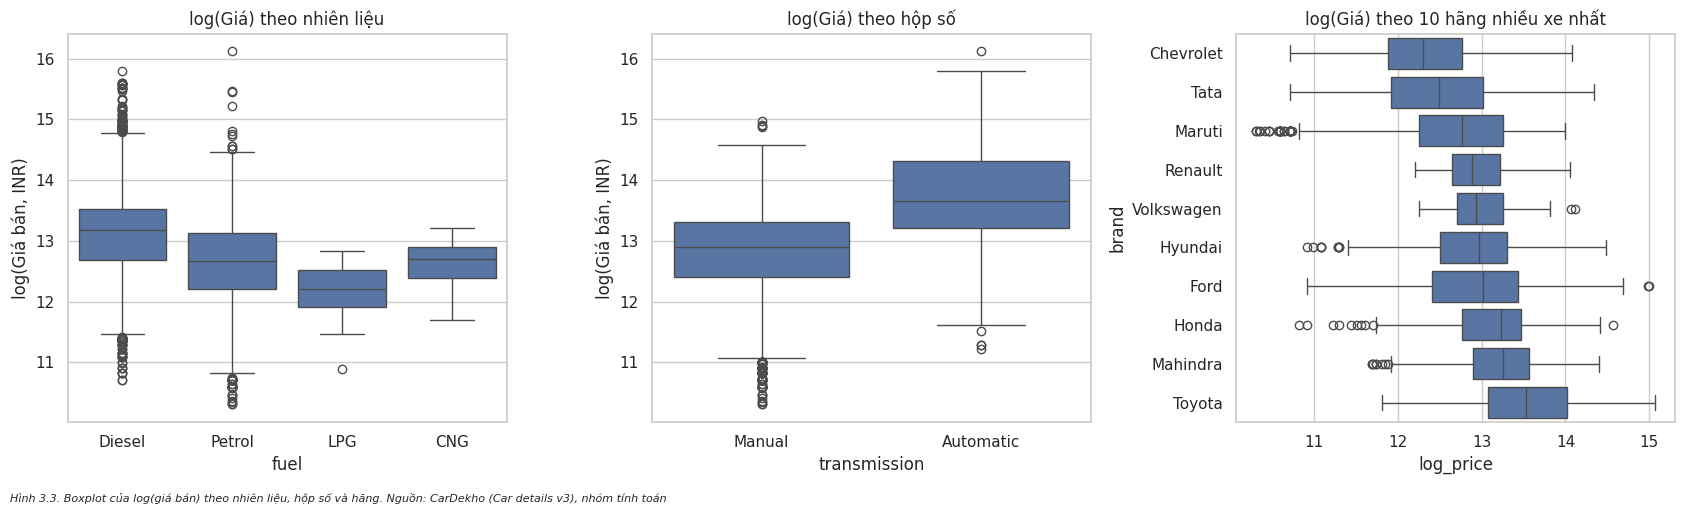

In [9]:
top_brands = df["brand"].value_counts().head(10).index
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
sns.boxplot(data=df, x="fuel", y="log_price", ax=ax[0]); ax[0].set_title("log(Giá) theo nhiên liệu")
sns.boxplot(data=df, x="transmission", y="log_price", ax=ax[1]); ax[1].set_title("log(Giá) theo hộp số")
order = df[df.brand.isin(top_brands)].groupby("brand")["log_price"].median().sort_values().index
sns.boxplot(data=df[df.brand.isin(top_brands)], y="brand", x="log_price", order=order, ax=ax[2])
ax[2].set_title("log(Giá) theo 10 hãng nhiều xe nhất")
for a in ax: a.set_xlabel(a.get_xlabel()); 
ax[0].set_ylabel("log(Giá bán, INR)"); ax[1].set_ylabel("log(Giá bán, INR)")
plt.tight_layout()
save_fig("hinh_3_3", "Hình 3.3. Boxplot của log(giá bán) theo nhiên liệu, hộp số và hãng")

## 6. Tương quan
**📘 Kiến thức XSTK**
- **Pearson r** đo quan hệ **tuyến tính**, nhạy với ngoại lai, $-1\le r\le 1$.
- **Spearman ρ** dựa trên **hạng**, đo quan hệ **đơn điệu**, hợp với dữ liệu lệch.
- **Tương quan không phải nhân quả.** Hai biến `engine` và `max_power` tương quan mạnh → báo trước cho TV4 về đa cộng tuyến (VIF).

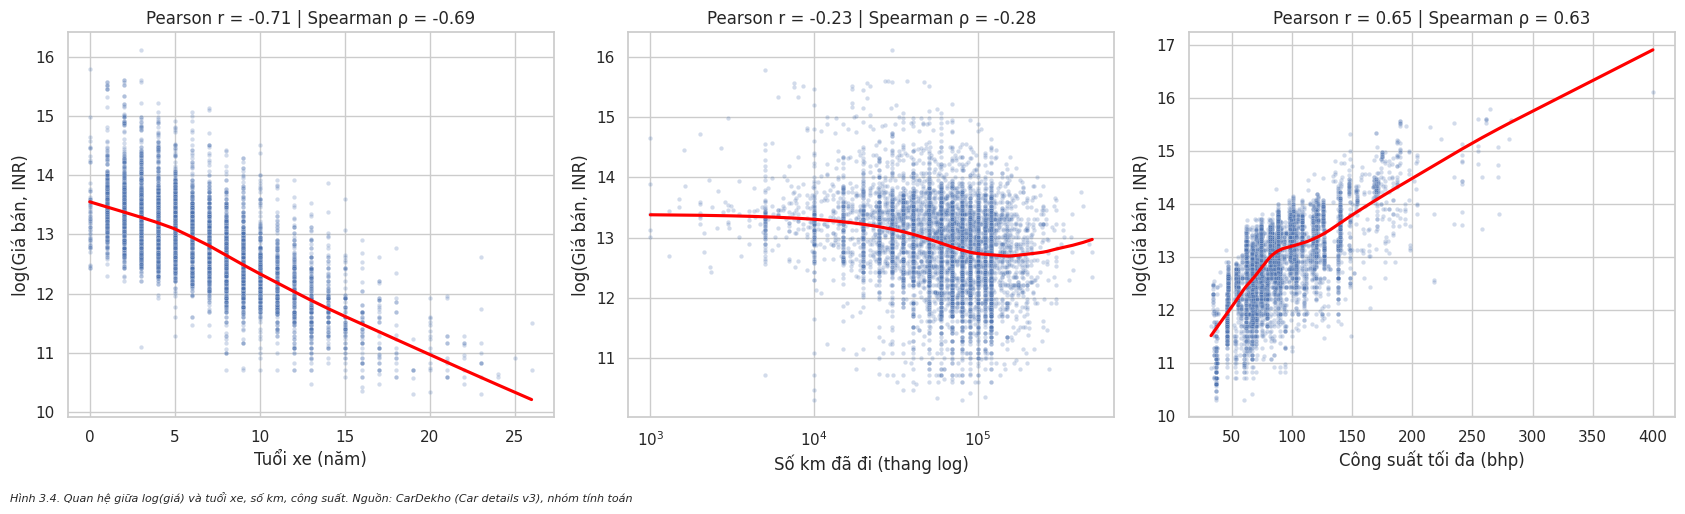

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, (x, xl) in zip(ax, [("car_age", "Tuổi xe (năm)"), ("km_driven", "Số km đã đi"), ("max_power", "Công suất tối đa (bhp)")]):
    if x in df.columns:
        sns.scatterplot(data=df, x=x, y="log_price", alpha=.25, s=10, ax=a)
        sns.regplot(data=df, x=x, y="log_price", scatter=False, lowess=True, line_kws={"color": "red"}, ax=a)
        a.set_xlabel(xl); a.set_ylabel("log(Giá bán, INR)")
        a.set_title(f"Pearson r = {df[x].corr(df['log_price']):.2f} | Spearman ρ = {df[x].corr(df['log_price'], method='spearman'):.2f}")
ax[1].set_xscale("log"); ax[1].set_xlabel("Số km đã đi (thang log)")
plt.tight_layout()
save_fig("hinh_3_4", "Hình 3.4. Quan hệ giữa log(giá) và tuổi xe, số km, công suất")

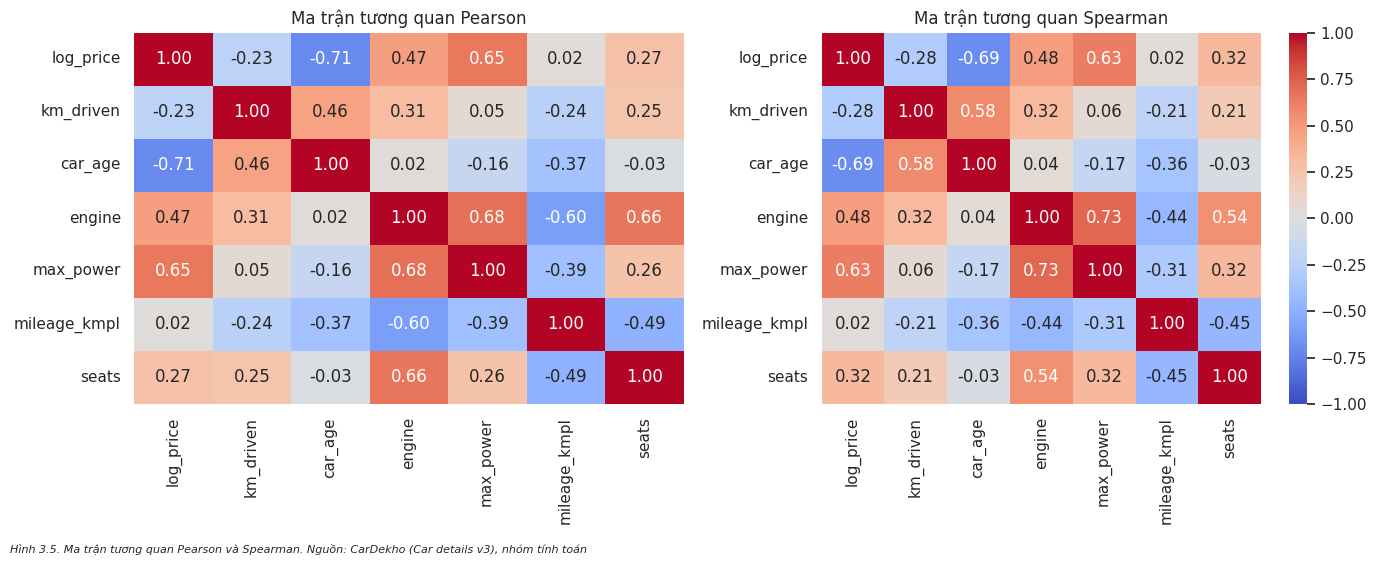

Chênh lệch |Pearson − Spearman| lớn nhất (ngoài đường chéo): 0.16


In [11]:
num = [c for c in ["log_price", "km_driven", "car_age", "engine", "max_power", "mileage_kmpl", "seats"] if c in df.columns]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, m, t in zip(ax, ["pearson", "spearman"], ["Pearson", "Spearman"]):
    sns.heatmap(df[num].corr(method=m), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=a, cbar=m == "spearman")
    a.set_title(f"Ma trận tương quan {t}")
plt.tight_layout()
save_fig("hinh_3_5", "Hình 3.5. Ma trận tương quan Pearson và Spearman")

diff = (df[num].corr("pearson") - df[num].corr("spearman")).abs()
print("Chênh lệch |Pearson − Spearman| lớn nhất (ngoài đường chéo):", round(diff.where(~np.eye(len(num), dtype=bool)).max().max(), 2))

## 7. Khoảng tin cậy 95%
**📘 Kiến thức XSTK (trọng tâm của TV2)**
- **Ước lượng điểm** ($\bar x$ là ước lượng không chệch của $\mu$) và **ước lượng khoảng**.
- **Sai số chuẩn** $SE=s/\sqrt n$. KTC cho trung bình khi $\sigma$ chưa biết: $\bar x \pm t_{\alpha/2,\,n-1}\cdot s/\sqrt n$ (phân phối Student).
- **CLT:** n lớn thì $\bar x$ xấp xỉ chuẩn, nhưng giá lệch mạnh nên làm trên log vẫn tốt hơn.
- **Diễn giải đúng:** nếu lặp lại việc lấy mẫu nhiều lần, khoảng 95% các khoảng như vậy chứa $\mu$. **Không** phải "xác suất μ nằm trong khoảng này là 95%".
- Độ rộng KTC **giảm khi n tăng**, **tăng khi s hoặc mức tin cậy tăng**.
- **Bootstrap:** tái chọn mẫu có hoàn lại để ước lượng phân phối mẫu của thống kê.
- **KTC cho tỷ lệ (Wilson):** tốt hơn công thức Wald khi n nhỏ hoặc $\hat p$ gần 0/1.

⚠️ Sau khi `exp`, KTC trên log là KTC của **trung bình nhân** (xấp xỉ trung vị của giá), **không phải** trung bình cộng.

In [12]:
def ci_log(x, conf=0.95):
    """KTC t trên log(giá) rồi đổi ngược bằng exp -> KTC cho trung bình nhân."""
    x = np.asarray(x, float); n = len(x)
    m, se = x.mean(), x.std(ddof=1) / np.sqrt(n)
    h = stats.t.ppf((1 + conf) / 2, n - 1) * se
    return n, np.exp(m), np.exp(m - h), np.exp(m + h)

def ci_boot(x, B=10_000, conf=0.95):
    """Bootstrap percentile cho trung bình cộng của giá gốc."""
    x = np.asarray(x, float); n = len(x)
    means = np.fromiter((rng.choice(x, n, replace=True).mean() for _ in range(B)), float, B)
    a = (1 - conf) / 2
    return x.mean(), np.quantile(means, a), np.quantile(means, 1 - a)

def ci_table(group_col):
    rows = []
    for g, s in df.groupby(group_col):
        n, gm, lo, hi = ci_log(s["log_price"])
        mean, blo, bhi = ci_boot(s["selling_price"])
        rows.append({"Nhóm": g, "n": n, "TB nhân (log→exp)": gm, "KTC dưới": lo, "KTC trên": hi,
                     "TB cộng": mean, "Bootstrap dưới": blo, "Bootstrap trên": bhi,
                     "Cảnh báo": "n < 30" if n < 30 else ("n nhỏ" if n < 100 else "")})
    return pd.DataFrame(rows).round(0).astype({"n": int})

# Gộp CNG và LPG (nhóm rất nhỏ), thống nhất với kiểm định của TV3
if "fuel_group" in df.columns:
    df["fuel_grp"] = df["fuel_group"]          # cột Khoa đã gộp sẵn (CNG + LPG)
else:
    df["fuel_grp"] = df["fuel"].replace({"CNG": "CNG/LPG", "LPG": "CNG/LPG"})
bang33 = ci_table("transmission"); bang34 = ci_table("fuel_grp")
bang33.to_csv(f"{FIG_DIR}/bang_3_3_ktc_hopso.csv", index=False, encoding="utf-8-sig")
bang34.to_csv(f"{FIG_DIR}/bang_3_4_ktc_nhienlieu.csv", index=False, encoding="utf-8-sig")
print("Bảng 3.3. KTC 95% của giá bán (INR) theo hộp số"); display(bang33)
print("Bảng 3.4. KTC 95% của giá bán (INR) theo nhiên liệu (gộp CNG và LPG)"); display(bang34)

Bảng 3.3. KTC 95% của giá bán (INR) theo hộp số


,Nhóm,n,TB nhân (log→exp),KTC dưới,KTC trên,TB cộng,Bootstrap dưới,Bootstrap trên,Cảnh báo
0,Automatic,566,934796.0,875448.0,998166.0,1293655.0,1196959.0,1394416.0,
1,Manual,6127,365464.0,359198.0,371839.0,452052.0,444700.0,459474.0,


Bảng 3.4. KTC 95% của giá bán (INR) theo nhiên liệu (gộp CNG và LPG)


,Nhóm,n,TB nhân (log→exp),KTC dưới,KTC trên,TB cộng,Bootstrap dưới,Bootstrap trên,Cảnh báo
0,CNG/LPG,85,251532.0,228301.0,277127.0,274976.0,252399.0,298448.0,n nhỏ
1,Diesel,3651,504230.0,493071.0,515641.0,646527.0,627597.0,666459.0,
2,Petrol,2957,297159.0,289605.0,304909.0,378117.0,366452.0,390939.0,


In [13]:
# Tỷ lệ xe số tự động: KTC Wilson, so với Wald
k, n = int((df["transmission"] == "Automatic").sum()), len(df)
p = k / n
w_lo, w_hi = proportion_confint(k, n, alpha=ALPHA, method="wilson")
z = stats.norm.ppf(1 - ALPHA / 2); se = np.sqrt(p * (1 - p) / n)
print(f"Tỷ lệ xe số tự động: {k}/{n} = {p:.2%}")
print(f"KTC 95% Wilson: [{w_lo:.2%}, {w_hi:.2%}]  |  Wald: [{p - z*se:.2%}, {p + z*se:.2%}]")

# Tỷ lệ theo nhiên liệu gộp (tuỳ chọn thêm vào báo cáo)
rows = []
for g, s in df.groupby("fuel_grp"):
    k_, n_ = int((s["transmission"] == "Automatic").sum()), len(s)
    lo, hi = proportion_confint(k_, n_, alpha=ALPHA, method="wilson")
    rows.append({"Nhóm": g, "n": n_, "Số xe tự động": k_, "Tỷ lệ": k_ / n_, "Wilson dưới": lo, "Wilson trên": hi})
display(pd.DataFrame(rows).round(3))

Tỷ lệ xe số tự động: 566/6693 = 8.46%
KTC 95% Wilson: [7.81%, 9.15%]  |  Wald: [7.79%, 9.12%]


,Nhóm,n,Số xe tự động,Tỷ lệ,Wilson dưới,Wilson trên
0,CNG/LPG,85,0,0.000,0.000,0.043
1,Diesel,3651,293,0.080,0.072,0.090
2,Petrol,2957,273,0.092,0.082,0.103


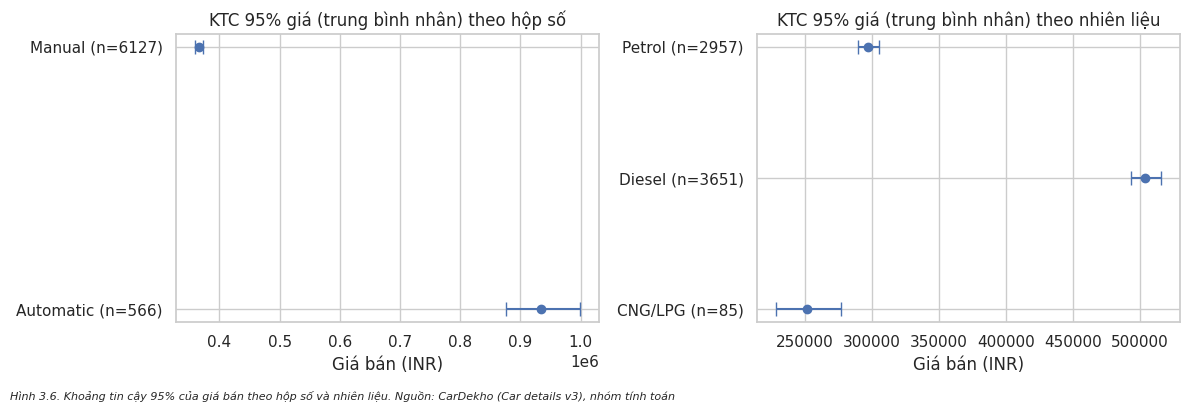

In [14]:
# Hình minh hoạ: KTC (trung bình nhân) theo nhóm, có ghi n
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, tab, title in zip(ax, [bang33, bang34], ["Hộp số", "Nhiên liệu"]):
    y = np.arange(len(tab))
    a.errorbar(tab["TB nhân (log→exp)"], y,
               xerr=[tab["TB nhân (log→exp)"] - tab["KTC dưới"], tab["KTC trên"] - tab["TB nhân (log→exp)"]],
               fmt="o", capsize=5)
    a.set_yticks(y); a.set_yticklabels([f"{g} (n={n})" for g, n in zip(tab["Nhóm"], tab["n"])])
    a.set_title(f"KTC 95% giá (trung bình nhân) theo {title.lower()}"); a.set_xlabel("Giá bán (INR)")
plt.tight_layout()
save_fig("hinh_3_6", "Hình 3.6. Khoảng tin cậy 95% của giá bán theo hộp số và nhiên liệu")

**Cách đọc KTC:** nếu hai KTC của hai nhóm **không chồng lấn**, đó là dấu hiệu khác biệt (kết luận chính thức nhờ kiểm định của TV3). Ghi **n từng nhóm**; nhóm nhỏ thì KTC rộng, cần cảnh báo.

## 8. Tóm tắt số liệu để viết mục 3.1

In [15]:
print(f"n = {len(df):,} xe; số biến phân tích = {df.shape[1]}")
print(f"Giá bán: trung bình {df.selling_price.mean():,.0f} | trung vị {df.selling_price.median():,.0f} INR | skew {sk_before:.2f} -> log: {sk_after:.2f}")
print(f"Xe số tự động: {p:.1%} (Wilson 95%: {w_lo:.1%}–{w_hi:.1%})")
g = bang33.set_index("Nhóm")
if {"Automatic", "Manual"} <= set(g.index):
    r = g.loc["Automatic", "TB nhân (log→exp)"] / g.loc["Manual", "TB nhân (log→exp)"]
    overlap = not (g.loc["Automatic", "KTC dưới"] > g.loc["Manual", "KTC trên"] or g.loc["Manual", "KTC dưới"] > g.loc["Automatic", "KTC trên"])
    print(f"Giá điển hình (TB nhân) số tự động / số sàn ≈ {r:.2f} lần; KTC chồng lấn: {overlap}")
print("\n--- Đối chiếu với nhật ký làm sạch của Khoa ---")
print(f"Số dòng: {len(df):,} (kỳ vọng 6.693) ->", "OK" if len(df) == 6693 else "KHÁC, kiểm tra lại file")
print(f"Skewness giá: {sk_before:.2f} -> log: {sk_after:.2f} (Khoa ghi 5,46 -> -0,17)")
print(f"Tỷ lệ xe số tự động: {p:.1%} (Khoa ghi khoảng 8,5%)")
print("\nCác file đã lưu trong", FIG_DIR, ":", sorted(os.listdir(FIG_DIR)))

n = 6,693 xe; số biến phân tích = 24
Giá bán: trung bình 523,223 | trung vị 420,000 INR | skew 5.46 -> log: -0.17
Xe số tự động: 8.5% (Wilson 95%: 7.8%–9.1%)
Giá điển hình (TB nhân) số tự động / số sàn ≈ 2.56 lần; KTC chồng lấn: False

--- Đối chiếu với nhật ký làm sạch của Khoa ---
Số dòng: 6,693 (kỳ vọng 6.693) -> OK
Skewness giá: 5.46 -> log: -0.17 (Khoa ghi 5,46 -> -0,17)
Tỷ lệ xe số tự động: 8.5% (Khoa ghi khoảng 8,5%)

Các file đã lưu trong figures : ['bang_3_1.csv', 'bang_3_2_tan_so.xlsx', 'bang_3_3_ktc_hopso.csv', 'bang_3_4_ktc_nhienlieu.csv', 'hinh_3_1.png', 'hinh_3_2.png', 'hinh_3_3.png', 'hinh_3_4.png', 'hinh_3_5.png', 'hinh_3_6.png']


### ✅ Checklist nghiệm thu
- [ ] Restart & Run All không lỗi, đọc từ `cleaned_cars.csv` v1.0
- [ ] Hình 3.1–3.6 (300 dpi), Bảng 3.1–3.4 đã lưu vào `figures/`
- [ ] Mỗi con số trong mục 3.1 truy được về một ô code
- [ ] Đã ghi chú: kurtosis dư; KTC log→exp là trung bình nhân; cỡ mẫu nhóm CNG/LPG
- [ ] Sang review chéo đã đồng ý